In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv("selected_features_for_clustering.csv")

print("Shape:", df.shape)
df.head()

Shape: (20000, 10)


,Routine_Task_Percentage,Creativity_Requirement,Tasks_Automated_Percentage,Job_Level_Encoded,Human_Interaction_Level,AI_Training_Hours,AI_Usage_Hours_Per_Week,Years_of_Experience,AI_Adoption_Level_Encoded,Number_of_AI_Tools_Used
0,84,21,40,0,94,26,7,6,1,5
1,30,84,14,0,68,9,2,14,0,2
2,12,86,6,2,71,3,1,7,0,0
3,90,18,67,0,21,26,10,6,1,3
4,49,52,26,0,72,19,13,12,1,5


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

print("Scaled shape:", X_scaled.shape)

Scaled shape: (20000, 10)


K-Means K=2 | Inertia=119379.55 | Silhouette=0.3489
K-Means K=3 | Inertia=97988.50 | Silhouette=0.3358
K-Means K=4 | Inertia=89885.48 | Silhouette=0.2244
K-Means K=5 | Inertia=83374.35 | Silhouette=0.1707
K-Means K=6 | Inertia=78149.01 | Silhouette=0.1666
K-Means K=7 | Inertia=74207.20 | Silhouette=0.1655
K-Means K=8 | Inertia=70692.78 | Silhouette=0.1578


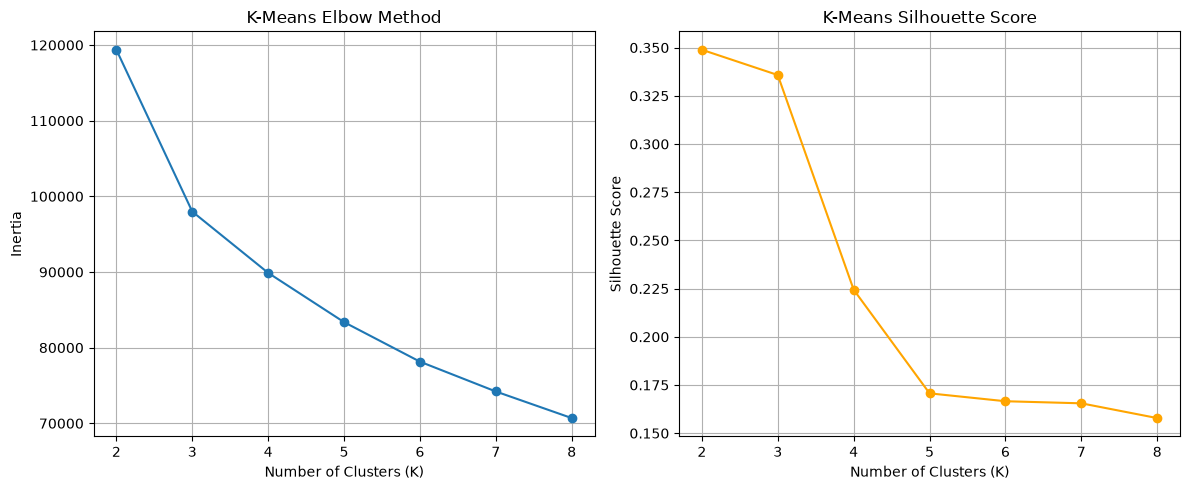

Best K for K-Means: 2


In [4]:
k_values = range(2, 9)

kmeans_inertia = []
kmeans_silhouette = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    kmeans_inertia.append(kmeans.inertia_)
    kmeans_silhouette.append(silhouette_score(X_scaled, labels))

    print(f"K-Means K={k} | Inertia={kmeans.inertia_:.2f} | Silhouette={kmeans_silhouette[-1]:.4f}")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(k_values, kmeans_inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(k_values, kmeans_silhouette, marker="o", color="orange")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-Means Silhouette Score")
plt.grid(True)

plt.tight_layout()
plt.show()

best_k_kmeans = k_values[kmeans_silhouette.index(max(kmeans_silhouette))]
print("Best K for K-Means:", best_k_kmeans)

Hierarchical K=2 | Silhouette=0.3465
Hierarchical K=3 | Silhouette=0.3340
Hierarchical K=4 | Silhouette=0.2153
Hierarchical K=5 | Silhouette=0.1402
Hierarchical K=6 | Silhouette=0.1219
Hierarchical K=7 | Silhouette=0.1194
Hierarchical K=8 | Silhouette=0.1224


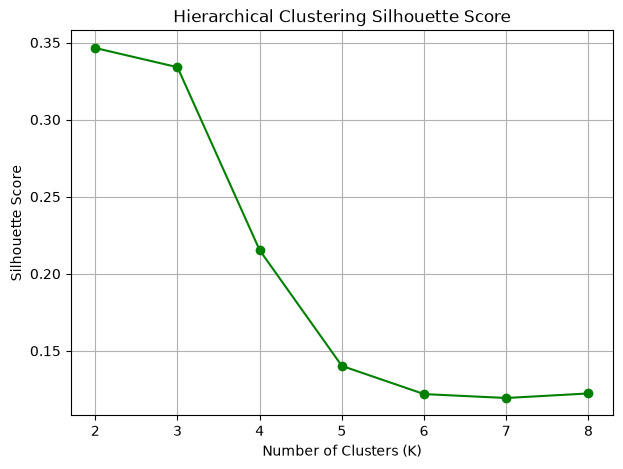

Best K for Hierarchical Clustering: 2


In [5]:
hier_silhouette = []

for k in k_values:
    model = AgglomerativeClustering(n_clusters=k)
    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    hier_silhouette.append(score)

    print(f"Hierarchical K={k} | Silhouette={score:.4f}")

plt.figure(figsize=(7, 5))
plt.plot(k_values, hier_silhouette, marker="o", color="green")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Hierarchical Clustering Silhouette Score")
plt.grid(True)
plt.show()

best_k_hierarchical = k_values[hier_silhouette.index(max(hier_silhouette))]
print("Best K for Hierarchical Clustering:", best_k_hierarchical)

In [7]:
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Reduce dimensions for faster GMM
pca = PCA(n_components=5, random_state=42)
X_pca_gmm = pca.fit_transform(X_scaled)

print("PCA shape for GMM:", X_pca_gmm.shape)

gmm_bic = []
gmm_aic = []
gmm_silhouette = []

k_values = range(2, 7)   # K=2 to 6 only

for k in k_values:
    gmm = GaussianMixture(
        n_components=k,
        random_state=42,
        n_init=1,
        max_iter=200,
        covariance_type="diag"   # faster than full covariance
    )
    
    labels = gmm.fit_predict(X_pca_gmm)

    gmm_bic.append(gmm.bic(X_pca_gmm))
    gmm_aic.append(gmm.aic(X_pca_gmm))
    gmm_silhouette.append(silhouette_score(X_pca_gmm, labels))

    print(f"GMM K={k} | BIC={gmm_bic[-1]:.2f} | AIC={gmm_aic[-1]:.2f} | Silhouette={gmm_silhouette[-1]:.4f}")

PCA shape for GMM: (20000, 5)
GMM K=2 | BIC=303301.33 | AIC=303135.35 | Silhouette=0.2966
GMM K=3 | BIC=296286.91 | AIC=296034.00 | Silhouette=0.3569
GMM K=4 | BIC=287934.86 | AIC=287595.01 | Silhouette=0.2189
GMM K=5 | BIC=287643.43 | AIC=287216.64 | Silhouette=0.1636
GMM K=6 | BIC=284277.26 | AIC=283763.53 | Silhouette=0.1382


In [9]:
import pandas as pd

# Default values
best_k_kmeans = globals().get("best_k_kmeans", None)
best_k_hierarchical = globals().get("best_k_hierarchical", None)
best_k_gmm_bic = globals().get("best_k_gmm_bic", None)
best_k_gmm_sil = globals().get("best_k_gmm_sil", None)

results = pd.DataFrame({
    "Model": [
        "K-Means",
        "Hierarchical",
        "GMM (BIC)",
        "GMM (Silhouette)"
    ],
    "Best_K": [
        best_k_kmeans,
        best_k_hierarchical,
        best_k_gmm_bic,
        best_k_gmm_sil
    ]
})

results

,Model,Best_K
0,K-Means,2.0
1,Hierarchical,2.0
2,GMM (BIC),NaN
3,GMM (Silhouette),NaN
